# 2. Modelovanje: transformer mreža

Ovo je isti zadatak i isti podaci kao u prvom projektu (MLP nad TF-IDF vektorima), ali je klasifikator **transformer**. Podela na trening/validaciju/test je ista (fajlovi iz sveske 01), pa su rezultati uporedivi.

Plan ove sveske:

1. tokenizacija: kako se naslov pretvara u niz brojeva,
2. arhitektura transformera i šta radi koji deo,
3. prva mreža i kriva učenja,
4. normalizacija teksta: da li je uopšte potrebna (poređenje sa i bez),
5. veličina rečnika (koliko retkih reči zadržati),
6. veličina mreže (širina i broj slojeva),
7. regularizacija (dropout),
8. konačan model i snimanje.

Sve se radi samo na trening i validacionom skupu. Test skup se otvara tek u svesci 03.

Koristim PyTorch za matrice i automatski izračunat backpropagation (`loss.backward()`), ali **model nije pretreniran**: svi slojevi se uče od nule na ovim naslovima. Ne koristim nikakve gotove jezičke modele.

In [1]:
import sys, time, warnings, os
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

from collections import Counter
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from model import build_vocab, encode, train, evaluate, TextTransformer
from textprep import VARIANTS

sns.set_theme(style="whitegrid")
torch.set_num_threads(4)
tr = pd.read_csv("../data/train.csv"); va = pd.read_csv("../data/val.csv")
classes = pd.read_csv("../data/classes.csv")
ytr = torch.tensor(tr["label"].values); yva = torch.tensor(va["label"].values)
print(len(tr), len(va))

def n_params(m):
    return sum(p.numel() for p in m.parameters())

def plot_hist(h, title):
    ep = np.arange(1, len(h["val_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(ep, h["train_loss"], label="trening"); ax[0].plot(ep, h["val_loss"], label="validacija")
    ax[0].axvline(h["best_epoch"], ls=":", c="gray"); ax[0].set_title("Gubitak (cross-entropy)"); ax[0].legend()
    ax[1].plot(ep, h["train_acc"], label="trening"); ax[1].plot(ep, h["val_acc"], label="validacija")
    ax[1].set_title("Tačnost"); ax[1].legend()
    for a in ax: a.set_xlabel("epoha")
    fig.suptitle(title); plt.tight_layout(); plt.show()

33204 4151


## 2.1 Tokenizacija

Mreža računa sa brojevima, pa se svaki naslov (već normalizovan u svesci 01) pretvara u niz celih brojeva:

* **Token = jedna reč.** Naslovi su kratki i reči nose skoro svo značenje (marka, model, vrsta proizvoda). Pravljenje subword rečnika (BPE) bi bilo složenije, a za ovakve kratke naslove nema očiglednog razloga.
* **Rečnik** se pravi samo iz trening skupa (da ništa iz validacije ili testa ne procuri). Svaka reč dobija svoj broj. Dva posebna broja: `PAD = 0` (dopuna kratkih naslova) i `UNK = 1` (reč koje nema u rečniku).
* **Fiksna dužina.** Naslovi se dopunjavaju sa PAD do iste dužine, da bi se mogli grupisati u batch. Dužinu biram iz raspodele dužina ispod.

In [2]:
lens = tr["text"].str.split().str.len()
print("dužina naslova u rečima, percentili 50/95/99/99.9:", np.percentile(lens, [50, 95, 99, 99.9]), "| najduži:", lens.max())
MAX_LEN = 14

cnt = Counter(w for t in tr["text"] for w in t.split())
print("različitih reči u treningu:", len(cnt), "| koje se pojavljuju samo jednom:", sum(n == 1 for n in cnt.values()))

vocab = build_vocab(tr["text"], min_count=2)
val_tokens = [w for t in va["text"] for w in t.split()]
print("rečnik (min_count=2):", len(vocab), "| udeo nepoznatih reči u validaciji:", round(np.mean([w not in vocab for w in val_tokens]), 4))
example = tr["text"].iloc[0]
print(repr(example), "->", encode([example], vocab, MAX_LEN)[0].tolist())

dužina naslova u rečima, percentili 50/95/99/99.9: [ 6. 10. 12. 14.] | najduži: 16
različitih reči u treningu: 20998 | koje se pojavljuju samo jednom: 11397


rečnik (min_count=2): 9601 | udeo nepoznatih reči u validaciji: 0.0892
'plac na drini reka drina' -> [6921, 6276, 3377, 7584, 3375, 0, 0, 0, 0, 0, 0, 0, 0, 0]


Dužinu postavljam na 14 reči: to pokriva 99.9% naslova, a duži se samo skrate (nepotrebno bi bilo dopunjavati sve naslove do najdužeg). Većina naslova ima oko 6 reči, ostalo su PAD pozicije koje mreža ignoriše.

## 2.2 Arhitektura

```
niz brojeva (14)
  -> Embedding reči (d)  +  Embedding pozicije (d)
  -> N x [ Self-attention  ->  Feed-forward ]  -> LayerNorm
  -> prosek vektora preko pravih reči
  -> Dense(10) + softmax
```

Šta radi svaki deo i zašto je tu:

* **Embedding reči:** svaka reč iz rečnika dobija vektor od `d` brojeva koji se uči. Slične reči (npr. "brusilica" i "brusilice") treba da dobiju slične vektore. 
* **Embedding pozicije:** self-attention sam po sebi ne zna redosled reči, pa se vektoru reči dodaje vektor njene pozicije.
* **Self-attention:** za svaku reč računa koliko joj je bitna svaka druga reč u naslovu i pravi novi vektor kao ponderisan zbir. Tako reč "Bosch" u naslovu "bosch gws" dobija i informaciju da je tu "gws" (model brusilice). To je ono što MLP nad TF-IDF nema: kontekst reči u istom naslovu.
* **Više glava (heads):** attention se radi paralelno nekoliko puta sa različitim težinama, pa svaka glava može da prati drugu vrstu veze.
* **Feed-forward:** mali Dense sloj posle attention-a, obrađuje svaku reč posebno.
* **Rezidualne veze i LayerNorm:** olakšavaju treniranje dubljih mreža 
* **Prosek preko reči:** treba mi jedan vektor za ceo naslov. Umesto posebnog CLS tokena uzimam prosek vektora reči, što je jednostavnije.
* **Dense(10) + softmax + cross-entropy:** isto kao u prvom projektu, izlaz je verovatnoća za svaku od 10 grupa.


In [3]:
vocab = build_vocab(tr["text"], min_count=2)
Xtr = encode(tr["text"], vocab, MAX_LEN); Xva = encode(va["text"], vocab, MAX_LEN)
BASE = dict(d_model=64, n_heads=4, n_layers=2, d_ff=128, dropout=0.1)
print(TextTransformer(len(vocab) + 2, **BASE))
print("parametara:", n_params(TextTransformer(len(vocab) + 2, **BASE)))

TextTransformer(
  (emb): Embedding(9603, 64, padding_idx=0)
  (pos): Embedding(14, 64)
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (out): Linear(in_features=64, out_features=10, bias=True)
)
parametara: 683082


## 2.3 Prva mreža

Počinjem srednjom veličinom: 64 dimenzije, 4 glave, 2 sloja (oko 0.7M parametara). Treniram epohu po epohu da bih video krive učenja.

epoha  1 | train loss 0.3406 acc 0.9001 | val loss 0.3604 acc 0.8954 | 14s


epoha  2 | train loss 0.1834 acc 0.9481 | val loss 0.2301 acc 0.9330 | 13s


epoha  3 | train loss 0.1171 acc 0.9660 | val loss 0.1828 acc 0.9475 | 15s


epoha  4 | train loss 0.0806 acc 0.9777 | val loss 0.1553 acc 0.9559 | 15s


epoha  5 | train loss 0.0577 acc 0.9836 | val loss 0.1427 acc 0.9605 | 17s


...

epoha  9 | train loss 0.0197 acc 0.9944 | val loss 0.1333 acc 0.9634 | 8s


epoha 10 | train loss 0.0172 acc 0.9953 | val loss 0.1305 acc 0.9665 | 8s


epoha 11 | train loss 0.0144 acc 0.9957 | val loss 0.1430 acc 0.9677 | 9s


epoha 12 | train loss 0.0127 acc 0.9964 | val loss 0.1383 acc 0.9665 | 8s


epoha 13 | train loss 0.0115 acc 0.9967 | val loss 0.1386 acc 0.9682 | 8s
najbolja epoha: 10, 169s


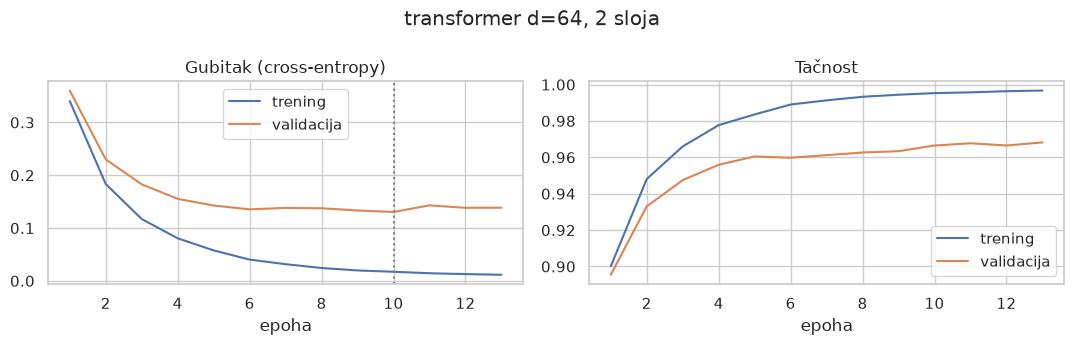

In [4]:
t = time.time()
net, h0 = train(Xtr, ytr, Xva, yva, len(vocab) + 2, verbose=True, **BASE)
print(f"najbolja epoha: {h0['best_epoch']}, {time.time()-t:.0f}s")
plot_hist(h0, "transformer d=64, 2 sloja")

Šta se vidi na krivama:

* Gubitak na treningu stalno pada (0.34 u prvoj epohi, 0.017 u desetoj), a validacioni gubitak staje oko epohe 5 do 10 (0.14 do 0.13). Razlika između treninga i validacije (tačnost 99.5% prema 96.7%) znači da mreža brzo uči trening skup napamet.
* Rano zaustavljanje je izabralo epohu 10 (validacioni gubitak 0.1305, tačnost 96.65%). Posle toga validacioni gubitak raste ili staje, pa dalje treniranje samo povećava jaz.


## 2.4 Normalizacija teksta: da li je potrebna?


Poredim četiri varijante ulaza, uvek iz originalnog naslova (`name`), sa istom mrežom i istim podacima, tako da se menja samo priprema teksta:

* **bez normalizacije:** originalni naslov, deli se samo po razmaku,
* **samo mala slova:** otklanja razliku između "Bosch" i "bosch",
* **mala slova + bez interpunkcije:** još i "drini,reka" postaje "drini reka", ali slova sa kvačicama ostaju,
* **puna normalizacija:** sve kao u svesci 01.

Ovo je jedna mreža po varijanti (jedan seed), pa razlike od oko 0.002 u gubitku ne smatram stvarnim.

In [5]:
nrows = []
for varijanta, fn in VARIANTS.items():
    t = time.time()
    a, b_ = tr["name"].map(fn), va["name"].map(fn)
    v = build_vocab(a, 2)
    A, B = encode(a, v, MAX_LEN), encode(b_, v, MAX_LEN)
    m, h = train(A, ytr, B, yva, len(v) + 2, **BASE)
    b = h["best_epoch"] - 1
    nrows.append(dict(varijanta=varijanta, recnik=len(v), nepoznato_u_val=np.mean([w not in v for s in b_ for w in s.split()]),
                      epoha=h["best_epoch"], train_loss=h["train_loss"][b], val_loss=h["val_loss"][b],
                      val_acc=h["val_acc"][b], sekundi=time.time() - t))
    print(nrows[-1], flush=True)
norm_df = pd.DataFrame(nrows).round(4); norm_df

{'varijanta': 'bez normalizacije', 'recnik': 12126, 'nepoznato_u_val': np.float64(0.15311397390662182), 'epoha': 11, 'train_loss': 0.03461647033691406, 'val_loss': 0.18726012110710144, 'val_acc': 0.9523006677627563, 'sekundi': 120.50473880767822}


{'varijanta': 'samo mala slova', 'recnik': 10477, 'nepoznato_u_val': np.float64(0.1294412078444244), 'epoha': 7, 'train_loss': 0.043652407824993134, 'val_loss': 0.1604737937450409, 'val_acc': 0.9547097086906433, 'sekundi': 85.00892519950867}


{'varijanta': 'mala slova + bez interpunkcije', 'recnik': 9863, 'nepoznato_u_val': np.float64(0.09245313251081558), 'epoha': 6, 'train_loss': 0.04253626987338066, 'val_loss': 0.14470802247524261, 'val_acc': 0.960491418838501, 'sekundi': 77.06058287620544}


{'varijanta': 'puna normalizacija', 'recnik': 9601, 'nepoznato_u_val': np.float64(0.08924851786572664), 'epoha': 10, 'train_loss': 0.01723046787083149, 'val_loss': 0.13045412302017212, 'val_acc': 0.9665141105651855, 'sekundi': 113.92498302459717}


,varijanta,recnik,nepoznato_u_val,epoha,train_loss,val_loss,val_acc,sekundi
0,bez normalizacije,12126,0.1531,11,0.0346,0.1873,0.9523,120.5047
1,samo mala slova,10477,0.1294,7,0.0437,0.1605,0.9547,85.0089
2,mala slova + bez interpunkcije,9863,0.0925,6,0.0425,0.1447,0.9605,77.0606
3,puna normalizacija,9601,0.0892,10,0.0172,0.1305,0.9665,113.9250


In [6]:
INP = norm_df.sort_values("val_loss").iloc[0]["varijanta"]
print("izabrana priprema teksta:", INP)
tr["inp"] = tr["name"].map(VARIANTS[INP]); va["inp"] = va["name"].map(VARIANTS[INP])

izabrana priprema teksta: puna normalizacija


**Rezultat: normalizacija pomaže, i svaki korak donosi poboljšanje.**

| ulaz | rečnik | nepoznatih reči u validaciji | validacioni gubitak | validaciona tačnost |
|---|---|---|---|---|
| bez normalizacije | 12126 | 15.3% | 0.1873 | 95.23% |
| samo mala slova | 10477 | 12.9% | 0.1605 | 95.47% |
| mala slova + bez interpunkcije | 9863 | 9.3% | 0.1447 | 96.05% |
| puna normalizacija | 9601 | 8.9% | **0.1305** | **96.65%** |

* Gubitak pada sa 0.187 na 0.131 i tačnost raste za 1.4 procentna poena. Svaki od tri koraka smanjuje gubitak za 0.014 do 0.027, što je više od razlike koju bih pripisao šumu jednog treniranja (oko 0.002).
* Razlog je rečnik: transformer ne zna da su "Plišana", "plisana" i "PLISANA" ista reč, već su to tri nepovezana tokena, a svaki ima malo primera. Normalizacija ih spaja, pa rečnik postaje manji i udeo nepoznatih reči pada sa 15.3% na 8.9%.
* Najveći pojedinačni dobitak daje uklanjanje velikih slova (0.027), zatim interpunkcije (0.016: "drini,reka" bi bez toga bila jedna nepoznata reč), pa dijakritika i ćirilice (0.014).
* Zaključak: normalizacija je potrebna i ostaje u projektu. Jedno ograničenje: svaka varijanta je trenirana jednom (jedan seed), a poređenje je urađeno samo sa ovim transformerom i rečnikom `min_count=2`.

## 2.5 Veličina rečnika
 
Veći `min_count` skraćuje rečnik, ali više reči postaje `UNK`. Poredim 1, 2 i 5 sa istom mrežom.

In [7]:
vrows = []
for mc in [1, 2, 5]:
    t = time.time()
    v = build_vocab(tr["inp"], mc)
    A = encode(tr["inp"], v, MAX_LEN); B = encode(va["inp"], v, MAX_LEN)
    m, h = train(A, ytr, B, yva, len(v) + 2, **BASE)
    b = h["best_epoch"] - 1
    vrows.append(dict(min_count=mc, recnik=len(v), epoha=h["best_epoch"], train_loss=h["train_loss"][b],
                      val_loss=h["val_loss"][b], val_acc=h["val_acc"][b], sekundi=time.time() - t))
    print(vrows[-1], flush=True)
vocab_df = pd.DataFrame(vrows).round(4); vocab_df

{'min_count': 1, 'recnik': 20998, 'epoha': 8, 'train_loss': 0.017016977071762085, 'val_loss': 0.18101491034030914, 'val_acc': 0.9590460062026978, 'sekundi': 104.77162027359009}


{'min_count': 2, 'recnik': 9601, 'epoha': 10, 'train_loss': 0.01723046787083149, 'val_loss': 0.13045412302017212, 'val_acc': 0.9665141105651855, 'sekundi': 113.82948613166809}


{'min_count': 5, 'recnik': 4204, 'epoha': 7, 'train_loss': 0.03415027633309364, 'val_loss': 0.11189814656972885, 'val_acc': 0.9686822295188904, 'sekundi': 82.98368740081787}


,min_count,recnik,epoha,train_loss,val_loss,val_acc,sekundi
0,1,20998,8,0.0170,0.1810,0.9590,104.7716
1,2,9601,10,0.0172,0.1305,0.9665,113.8295
2,5,4204,7,0.0342,0.1119,0.9687,82.9837


In [8]:
MIN_COUNT = int(vocab_df.sort_values("val_loss").iloc[0]["min_count"])
print("izabran min_count:", MIN_COUNT)
vocab = build_vocab(tr["inp"], MIN_COUNT)
Xtr = encode(tr["inp"], vocab, MAX_LEN); Xva = encode(va["inp"], vocab, MAX_LEN)

izabran min_count: 5


| `min_count` | rečnik | validacioni gubitak | validaciona tačnost |
|---|---|---|---|
| 1 | 20998 | 0.1810 | 95.90% |
| 2 | 9601 | 0.1305 | 96.65% |
| 5 | 4204 | **0.1119** | **96.87%** |



## 2.6 Veličina mreže

Dva načina da se mreža poveća: **šira** (veći `d_model`, više brojeva po reči) ili **dublja** (više slojeva attention + feed-forward). Isprobavam pet kombinacija, uvek sa 4 glave i `d_ff = 2 * d_model`. Manja mreža može da bude premala (loš i trening i validacija), veća može da zapamti trening (trening gubitak skoro nula, validacioni lošiji).

In [9]:
runs, srows = {}, []
for d, L in [(32, 1), (64, 1), (64, 2), (128, 2), (128, 4)]:
    t = time.time()
    m, h = train(Xtr, ytr, Xva, yva, len(vocab) + 2, d_model=d, n_heads=4, n_layers=L, d_ff=2 * d, dropout=0.1)
    runs[(d, L)] = (m, h)
    b = h["best_epoch"] - 1
    srows.append(dict(d_model=d, slojeva=L, parametara=n_params(m), epoha=h["best_epoch"], train_loss=h["train_loss"][b],
                      val_loss=h["val_loss"][b], train_acc=h["train_acc"][b], val_acc=h["val_acc"][b], sekundi=time.time() - t))
    print(srows[-1], flush=True)
size_df = pd.DataFrame(srows).round(4); size_df

{'d_model': 32, 'slojeva': 1, 'parametara': 143914, 'epoha': 17, 'train_loss': 0.028734171763062477, 'val_loss': 0.12156684696674347, 'train_acc': 0.9921395182609558, 'val_acc': 0.9701277017593384, 'sekundi': 53.87860822677612}


{'d_model': 64, 'slojeva': 1, 'parametara': 304202, 'epoha': 12, 'train_loss': 0.019161183387041092, 'val_loss': 0.12137743085622787, 'train_acc': 0.9946090579032898, 'val_acc': 0.9698867797851562, 'sekundi': 67.34614729881287}


{'d_model': 64, 'slojeva': 2, 'parametara': 337674, 'epoha': 7, 'train_loss': 0.03415027633309364, 'val_loss': 0.11189814656972885, 'train_acc': 0.9901216626167297, 'val_acc': 0.9686822295188904, 'sekundi': 83.01423811912537}


{'d_model': 128, 'slojeva': 2, 'parametara': 806410, 'epoha': 5, 'train_loss': 0.03548205643892288, 'val_loss': 0.12330252677202225, 'train_acc': 0.9900915622711182, 'val_acc': 0.9667549729347229, 'sekundi': 148.647691488266}


{'d_model': 128, 'slojeva': 4, 'parametara': 1071370, 'epoha': 7, 'train_loss': 0.0341961570084095, 'val_loss': 0.10920077562332153, 'train_acc': 0.9897903800010681, 'val_acc': 0.9718140363693237, 'sekundi': 333.93964314460754}


,d_model,slojeva,parametara,epoha,train_loss,val_loss,train_acc,val_acc,sekundi
0,32,1,143914,17,0.0287,0.1216,0.9921,0.9701,53.8786
1,64,1,304202,12,0.0192,0.1214,0.9946,0.9699,67.3461
2,64,2,337674,7,0.0342,0.1119,0.9901,0.9687,83.0142
3,128,2,806410,5,0.0355,0.1233,0.9901,0.9668,148.6477
4,128,4,1071370,7,0.0342,0.1092,0.9898,0.9718,333.9396


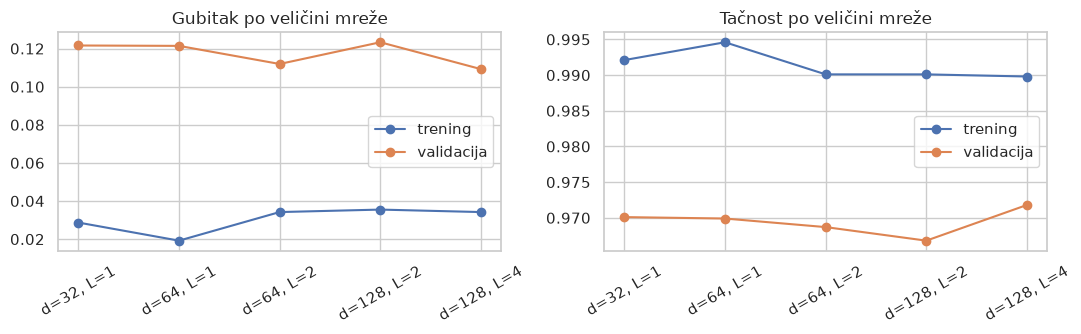

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
lab = [f"d={r.d_model}, L={r.slojeva}" for r in size_df.itertuples()]
x = np.arange(len(size_df))
ax[0].plot(x, size_df["train_loss"], "o-", label="trening"); ax[0].plot(x, size_df["val_loss"], "o-", label="validacija")
ax[0].set_xticks(x); ax[0].set_xticklabels(lab, rotation=30); ax[0].set_title("Gubitak po veličini mreže"); ax[0].legend()
ax[1].plot(x, size_df["train_acc"], "o-", label="trening"); ax[1].plot(x, size_df["val_acc"], "o-", label="validacija")
ax[1].set_xticks(x); ax[1].set_xticklabels(lab, rotation=30); ax[1].set_title("Tačnost po veličini mreže"); ax[1].legend()
plt.tight_layout(); plt.show()

| `d_model` | slojeva | parametara | validacioni gubitak | validaciona tačnost |
|---|---|---|---|---|
| 32 | 1 | 144k | 0.1216 | 97.01% |
| 64 | 1 | 304k | 0.1214 | 96.99% |
| 64 | 2 | 338k | 0.1119 | 96.87% |
| 128 | 2 | 806k | 0.1233 | 96.68% |
| 128 | 4 | 1.07M | **0.1092** | **97.18%** |

* Razlike su male (gubitak 0.109 do 0.123, tačnost 96.7% do 97.2%) i nisu monotone: veća mreža nije uvek bolja (`d=128, 2 sloja` je lošija od `d=32, 1 sloj`). Zato ne tvrdim da je izabrana mreža stvarno bolja od manjih, već samo da ima najmanji gubitak u ovom jednom treniranju.
* Najmanja mreža (144k parametara) je praktično jednako dobra kao najveća (7x više parametara, 6x sporije treniranje). Kapacitet, dakle, nije ono što ograničava rezultat.
* Sve mreže se preprilagode brzo (najbolja epoha 5 do 17, trening gubitak 0.02 do 0.04 naspram validacionih 0.11 do 0.12).
* Izabrana je `d=128, 4 sloja`, po pravilu "najmanji validacioni gubitak". Pošto su razlike u okviru šuma, mogla je da bude i manja mreža.

## 2.7 Regularizacija: dropout

**Dropout** tokom treniranja nasumično isključuje deo aktivacija, pa mreža ne može da se osloni na jednu putanju i teže pamti trening skup. Premali dropout ne radi ništa, preveliki sprečava učenje. Probam 0, 0.1 i 0.3 na najboljoj veličini iz 2.6. (Weight decay ostaje na 0.01, tu nisam ništa menjao.)

In [11]:
best = size_df.sort_values("val_loss").iloc[0]
D, L = int(best["d_model"]), int(best["slojeva"])
print("najbolja veličina:", D, L)
drun, drows = {}, []
for p in [0.0, 0.1, 0.3]:
    t = time.time()
    if p == 0.1:
        m, h = runs[(D, L)]
    else:
        m, h = train(Xtr, ytr, Xva, yva, len(vocab) + 2, d_model=D, n_heads=4, n_layers=L, d_ff=2 * D, dropout=p)
    drun[p] = (m, h)
    b = h["best_epoch"] - 1
    drows.append(dict(dropout=p, epoha=h["best_epoch"], train_loss=h["train_loss"][b], val_loss=h["val_loss"][b],
                      train_acc=h["train_acc"][b], val_acc=h["val_acc"][b]))
    print(drows[-1], flush=True)
drop_df = pd.DataFrame(drows).round(4); drop_df

najbolja veličina: 128 4


{'dropout': 0.0, 'epoha': 6, 'train_loss': 0.03782659024000168, 'val_loss': 0.1281713843345642, 'train_acc': 0.9873509407043457, 'val_acc': 0.9636232256889343}


{'dropout': 0.1, 'epoha': 7, 'train_loss': 0.0341961570084095, 'val_loss': 0.10920077562332153, 'train_acc': 0.9897903800010681, 'val_acc': 0.9718140363693237}


{'dropout': 0.3, 'epoha': 10, 'train_loss': 0.029750078916549683, 'val_loss': 0.10366949439048767, 'train_acc': 0.991266131401062, 'val_acc': 0.9735003709793091}


,dropout,epoha,train_loss,val_loss,train_acc,val_acc
0,0.0,6,0.0378,0.1282,0.9874,0.9636
1,0.1,7,0.0342,0.1092,0.9898,0.9718
2,0.3,10,0.0298,0.1037,0.9913,0.9735


| dropout | validacioni gubitak | validaciona tačnost |
|---|---|---|
| 0.0 | 0.1282 | 96.36% |
| 0.1 | 0.1092 | 97.18% |
| 0.3 | **0.1037** | **97.35%** |

Dropout pomaže: bez njega je gubitak 0.128, a sa 0.3 pada na 0.104 (tačnost +1 procentni poen). Veći dropout otežava mreži da pamti trening primere, što je baš problem koji se vidi u 2.3. Ograničenje: 0.3 je najveća ispitana vrednost i trend se još nije zaustavio, pa 0.5 nisam probao.

## 2.8 Konačan model i snimanje

Konačan model je kombinacija koja je u 2.4 do 2.7 imala najmanji validacioni gubitak (već je istrenirana, pa je ne treniram ponovo). Snimam težine, rečnik i imena klasa u jedan fajl, pa ga učitavam nazad i proveravam da daje isti rezultat. Validacioni rezultat je optimističan jer se na njemu birala konfiguracija; prava procena je test skup u svesci 03.

In [12]:
best_p = float(drop_df.sort_values("val_loss").iloc[0]["dropout"])
model, h = drun[best_p]
ARCH = dict(d_model=D, n_heads=4, n_layers=L, d_ff=2 * D, dropout=best_p)
b = h["best_epoch"] - 1
print("konačna arhitektura:", ARCH, "| min_count:", MIN_COUNT, "| parametara:", n_params(model))
print(f"najbolja epoha {h['best_epoch']}, val acc {h['val_acc'][b]:.4f}, val loss {h['val_loss'][b]:.4f}")

os.makedirs("../models", exist_ok=True)
torch.save({"vocab": vocab, "max_len": MAX_LEN, "prep": INP, "arch": ARCH, "state_dict": model.state_dict(),
            "classes": classes["group_name"].tolist()}, "../models/transformer_model.pt")
print(round(os.path.getsize("../models/transformer_model.pt") / 1e6, 1), "MB")

saved = torch.load("../models/transformer_model.pt")
check = TextTransformer(len(saved["vocab"]) + 2, **saved["arch"]); check.load_state_dict(saved["state_dict"])
print("val acc učitanog modela:", round(evaluate(check, Xva, yva)[1], 4))

konačna arhitektura: {'d_model': 128, 'n_heads': 4, 'n_layers': 4, 'd_ff': 256, 'dropout': 0.3} | min_count: 5 | parametara: 1071370
najbolja epoha 10, val acc 0.9735, val loss 0.1037
4.4 MB


val acc učitanog modela: 0.9735
